# The Problem

    RMS Titanic was a British passenger liner that sank in the North Atlantic Ocean in the early hours of 15 April 1912, after it collided with an iceberg during its maiden voyage from Southampton to New York City. There were an estimated 2,224 passengers and crew aboard the ship, and more than 1,500 died, making it one of the deadliest commercial peacetime maritime disasters in modern history. The RMS Titanic was the largest ship afloat at the time it entered service and was the second of three Olympic-class ocean liners operated by the White Star Line. The Titanic was built by the Harland and Wolff shipyard in Belfast. Thomas Andrews, her architect, also died in the disaster.

    Titanic dataset is one of the most famous specifically in the Data Science community. It is more so because the core of the problem is engaging to us humans. The information available enables an analyst to go through the lifecycle of a predictive analytics problem. This is a great place to start off building predictive models for a novel Data scientist/ analyst.

### Import Libraries

In [285]:
# linear algebra
import numpy as np 

# data processing
import pandas as pd
pd.set_option('display.max_columns',15)

# data visualization
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt
from matplotlib import style
import missingno

from sklearn.preprocessing import LabelEncoder
from sklearn import model_selection
from sklearn import metrics

# Algorithms
from sklearn import linear_model
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

In [3]:
test_df = pd.read_csv("/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/DataTales/DT01-Titanic/test_titanic.csv")
train_df = pd.read_csv("/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/DataTales/DT01-Titanic/train_titanic.csv")

## The lifecycle
    A common idea for Data Science project's flow:
        1. Data Collection/ Extraction
        2. Business Understanding
        3. Data Understanding
        4. Data Processing
        5. Exploratory Data Analysis
        6. Feature Engineering
        7. Feature Selection
        8. Model Building
        9. Model Evaluation
        10. Model Refining
    
    However, the aforementioned is debatable and changes with the problem at hand. In any case it is higly likely that all or most of the steps are existent in an end-to-end project not necessarily in the same order

In [4]:
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
PassengerId    891 non-null int64
Survived       891 non-null int64
Pclass         891 non-null int64
Name           891 non-null object
Sex            891 non-null object
Age            714 non-null float64
SibSp          891 non-null int64
Parch          891 non-null int64
Ticket         891 non-null object
Fare           891 non-null float64
Cabin          204 non-null object
Embarked       889 non-null object
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


#### What each field specifies
    survival:    Did the passenger survive?
    pclass:      Passenger's ticket class
    sex:         Sex	
    Age:	     Age in years	
    sibsp:	   # of siblings/spouses aboard the Titanic	
    parch:  	 # of parents/children aboard the Titanic	
    ticket: 	 Ticket number	
    fare:   	 Passenger fare	
    cabin:  	 Cabin number	
    embarked:    Port of Embarkation
    passengerid: Unique id of the passenger

    Now that you had a look at the data snippet, can you tell what steps are needed in predicting the survival of a person abord RMS Titanic?
---

    We won't need data extraction for sure, since we have the data at hand. There is no business involved and hence no business understanding needed. We'll perform pretty much everything else.

In [46]:
#Let's convert the age field to Integer from Float
train_df['Age'] = train_df['Age'].astype(int)
train_df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,Title
0,0,3,"Braund, Mr. Owen Harris",male,22,1,0,7.2500,S,Mr
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38,1,0,71.2833,C,Mrs
2,1,3,"Heikkinen, Miss. Laina",female,26,0,0,7.9250,S,Miss
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35,1,0,53.1000,S,Mrs
4,0,3,"Allen, Mr. William Henry",male,35,0,0,8.0500,S,Mr


In [47]:
train_df.describe(include='all')

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,Title
count,891.000000,891.000000,891,891,891.000000,891.000000,891.000000,891.000000,891,891
unique,NaN,NaN,891,2,NaN,NaN,NaN,NaN,3,5
top,NaN,NaN,"Tornquist, Mr. William Henry",male,NaN,NaN,NaN,NaN,S,Mr
freq,NaN,NaN,1,577,NaN,NaN,NaN,NaN,646,517
mean,0.383838,2.308642,NaN,NaN,29.638608,0.523008,0.381594,32.204208,NaN,NaN
std,0.486592,0.836071,NaN,NaN,13.293812,1.102743,0.806057,49.693429,NaN,NaN
min,0.000000,1.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,0.000000,2.000000,NaN,NaN,21.000000,0.000000,0.000000,7.910400,NaN,NaN
50%,0.000000,3.000000,NaN,NaN,30.000000,0.000000,0.000000,14.454200,NaN,NaN
75%,1.000000,3.000000,NaN,NaN,35.000000,1.000000,0.000000,31.000000,NaN,NaN


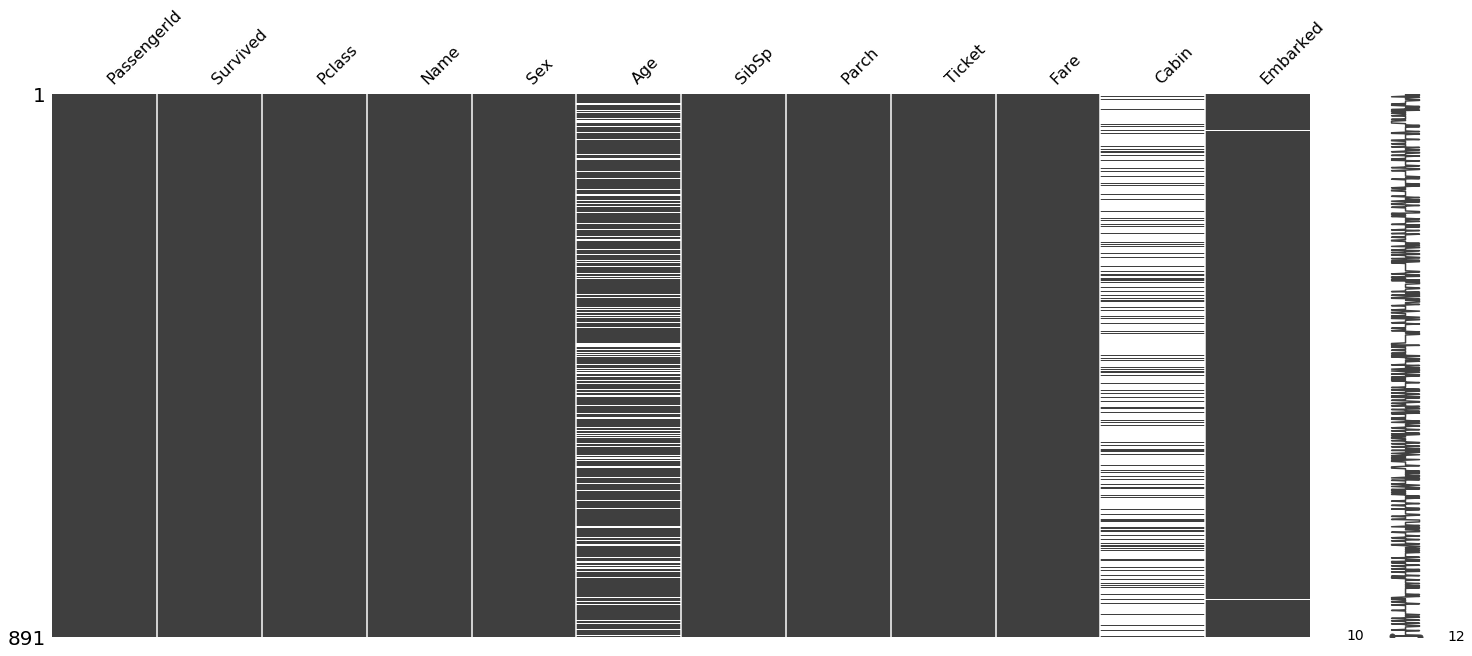

In [9]:
missingno.matrix(train_df)

    The white horizontal stripes specifies indices with null values. This is a handy method to visually understand presence of nulls but we will also look at the numbers to make a final decision as of how to deal with them.

In [12]:
train_df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [13]:
pd.value_counts(train_df['PassengerId'])

891    1
293    1
304    1
303    1
302    1
      ..
591    1
590    1
589    1
588    1
1      1
Name: PassengerId, Length: 891, dtype: int64

In [15]:
#We can readily drop the PassengerID, Cabin fields
train_df.drop(labels=['PassengerId','Cabin'],inplace=True,axis=1)
train_df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


    There are still fields with null values
        1. Age: 177
        2. Embarked: 2
    What do we do with them?
---

    We need to come up with a mechanism to impute in age but for embarked we can directly impute the most common embarking port

In [18]:
train_df['Embarked'].fillna(value=train_df['Embarked'].mode()[0],inplace=True)
train_df.isna().sum()

Survived      0
Pclass        0
Name          0
Sex           0
Age         177
SibSp         0
Parch         0
Ticket        0
Fare          0
Embarked      0
dtype: int64

    To fix the age field, I will extract title from the name and impute null ages with the mean age of other passengers with same title

In [20]:
train_df['Title']=train_df['Name'].apply(lambda val: val.split(',')[1].split('.')[0].strip())
train_df['Title'].value_counts()

Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Mlle              2
Major             2
Col               2
Lady              1
Ms                1
Sir               1
Jonkheer          1
the Countess      1
Mme               1
Capt              1
Don               1
Name: Title, dtype: int64

    Considering the meaning of some titles, I will rename them to be top

In [21]:
train_df['Title'].replace({'Ms':'Miss'},inplace=True)
train_df['Title'].replace(['Dr','Rev','Major','Col','Mlle','Lady','Mme','Capt','Jonkheer','the Countess','Don','Sir'],'Top',
                            inplace=True)
train_df['Title'].value_counts()

Mr        517
Miss      183
Mrs       125
Master     40
Top        26
Name: Title, dtype: int64

In [23]:
avg_age_title = {}
for title in pd.unique(train_df['Title']):
    avg_age_title[title] = np.mean(train_df[train_df['Title']==title]['Age'])

age=list()
###now fill the NAN in Age with the average of all people having the same title
for ind in list(train_df[(train_df['Age'].isna()==True)].index):
    train_df['Age'][ind]=avg_age_title[train_df.loc[ind]['Title']]

train_df.isna().sum()

/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  


Survived    0
Pclass      0
Name        0
Sex         0
Age         0
SibSp       0
Parch       0
Ticket      0
Fare        0
Embarked    0
Title       0
dtype: int64

    Awesome! now that the data is all cleaned up, we can start getting our hands dirty. We'll now try to understand the data    
    Let's address this chronologically, for passengers to be in the ship tickets are necessary. So let's explore the ticket and fare fields first.
    I know what you might be thinking, what good does a ticket do to predict survival? why don't you take a jab at it yourself?
---

    When it comes to analytics, we can't readily say this is useful and that isn't. So we analyze the values to understand if we can find patterns otherwise we can drop it.

In [7]:
train_df['Ticket'].value_counts()

1601        7
CA. 2343    7
347082      7
CA 2144     6
3101295     6
           ..
PC 17482    1
350029      1
347069      1
2686        1
113503      1
Name: Ticket, Length: 681, dtype: int64

    There is some pattern across the data: codes before a number, that might actually mean something. But we won't get into what it might mean because if you notice there are 681 unique entries and the overall data points we had is only 891. Hence it's not much of use and we'll drop it.

In [24]:
train_df.drop(labels=['Ticket'],axis=1,inplace=True)
train_df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,Title
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,S,Mr
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,71.2833,C,Mrs
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,S,Miss
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,S,Mrs
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,S,Mr


In [42]:
train_df['Fare'].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

([], <a list of 0 Text yticklabel objects>)

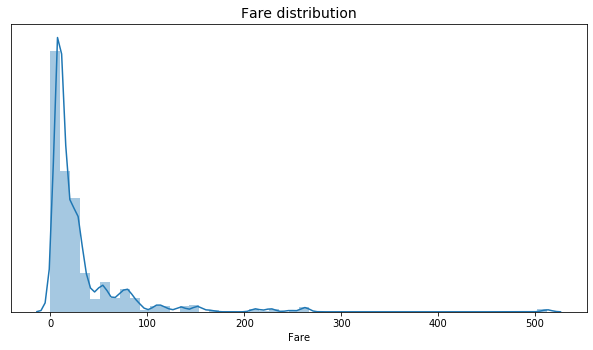

In [70]:
fig = plt.figure(figsize=(8,4))
ax = fig.add_axes([1,1,1,1])
ax.set_title('Fare distribution',fontsize=14)
sns.distplot(train_df['Fare'],ax=ax)
plt.yticks([])

    Most people that travelled on Titanic have low Fares and very few people actually have high priced tickets. Moreover, 75% of the Fares are <= 31
    I donno about you, but fare of 0 seems very intriguing to me. I would like to know more about this passenger(s), so keep this in mind will you?

    While buying the ticket, passengers are also expected to submit their personal details. Let's look at the Name, Age, Sex, SibSp, and Parch.

In [71]:
len(pd.unique(train_df['Name']))

891

In [206]:
#The name field by itself might not be very useful but the last name might say something
#We'll also drop the Name column
train_df['Last_Name'] = train_df['Name'].apply(lambda val: val.split(',')[0])
train_df.drop(labels='Name',axis=1,inplace=True)
train_df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,Last_Name
0,0,3,male,22,1,0,7.2500,S,Mr,Braund
1,1,1,female,38,1,0,71.2833,C,Mrs,Cumings
2,1,3,female,26,0,0,7.9250,S,Miss,Heikkinen
3,1,1,female,35,1,0,53.1000,S,Mrs,Futrelle
4,0,3,male,35,0,0,8.0500,S,Mr,Allen


(-0.5, 999.5, 599.5, -0.5)

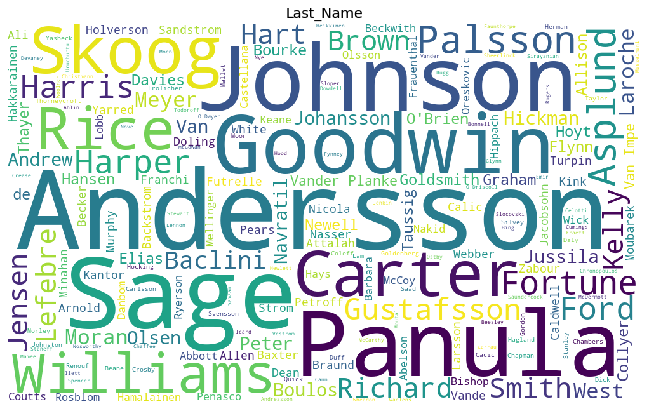

In [88]:
from wordcloud import WordCloud
wc = WordCloud(width=1000,height=600,background_color='white')
plt.figure(figsize=(12,7))
plt.title('Last_Name',fontsize=14)
plt.imshow(wc.generate(' '.join(train_df['Last_Name'].values)))
plt.axis('off')

    There are few Last_names that are repeated, this might mean there are families aboard the RMS Titanic. Don't be sceptical with me, we obviously know there were families aboard Titanic but from the data standpoint we just found out there might be chances of families. How can we confirm our observation though?
---
    
    You guessed it right, we will check the parch and sibsp fields

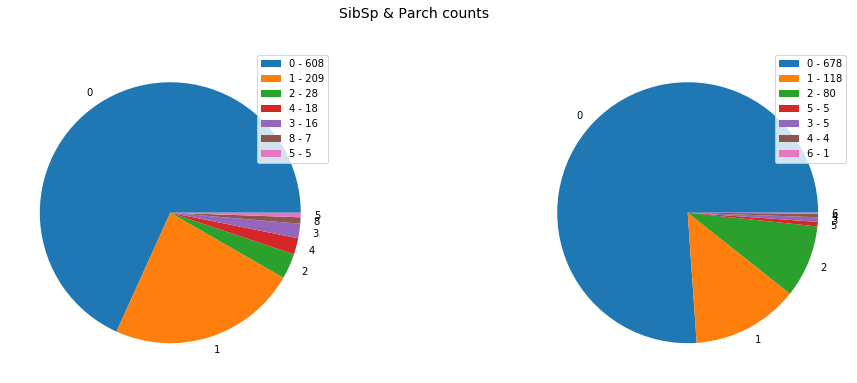

In [154]:
fig, axs = plt.subplots(1,2,figsize=(17,6))
plt.suptitle('SibSp & Parch counts',fontsize=14)
cols = ['SibSp','Parch']
axs = axs.flatten()
for col,ind in zip(cols,range(len(cols))):
    #sns.countplot(col,data=train_df,ax=axs[ind])
    val_counts = train_df[col].value_counts()
    axs[ind].pie(val_counts.values,labels=val_counts.keys())
    labels = np.char.add(np.char.add(np.array(val_counts.keys()).astype(str),' - '),val_counts.values.astype(str))
    axs[ind].legend(labels=labels,loc='upper right')
    

    Great! our previous observation seems to be true, there are higher values in Siblings/Spouse and Parents/Children

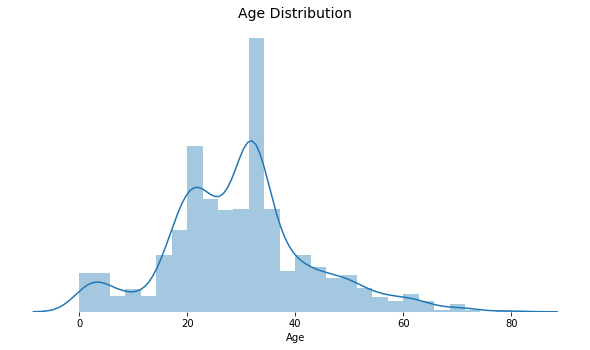

In [167]:
fig = plt.figure(figsize=(8,4))
ax = fig.add_axes([1,1,1,1])
plt.title('Age Distribution',fontsize=14)
sns.distplot(train_df['Age'],ax=ax)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

    Most people are middle-aged. We are essentially removing the visibility of spines to not show the plot borders. But why can't we use plt.axis('off')? that's a single line, right?
---

    When we use plt.axis('off') we won't be able to see labels or ticks on any axis. Hence the lengthier method

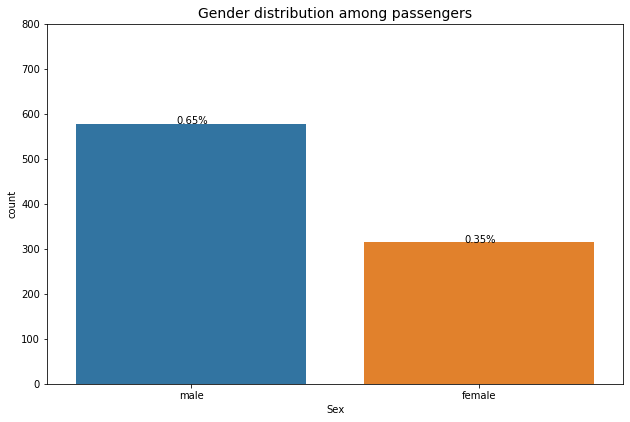

In [196]:
fig = plt.figure(figsize=(8,5))
ax = fig.add_axes([1,1,1,1])
ax.set_title('Gender distribution among passengers',fontsize=14)
sns.countplot(train_df['Sex'],ax=ax)
ax.set_ylim(0,800)

records = len(train_df)
for p in ax.patches:
    ax.annotate(s='{:.2f}%'.format(p.get_height()/records),xy=(p.get_x()+0.35,p.get_height()+0.3))


    Once a passenger buys a ticket, a class and embarking port are assigned. Let's look at them

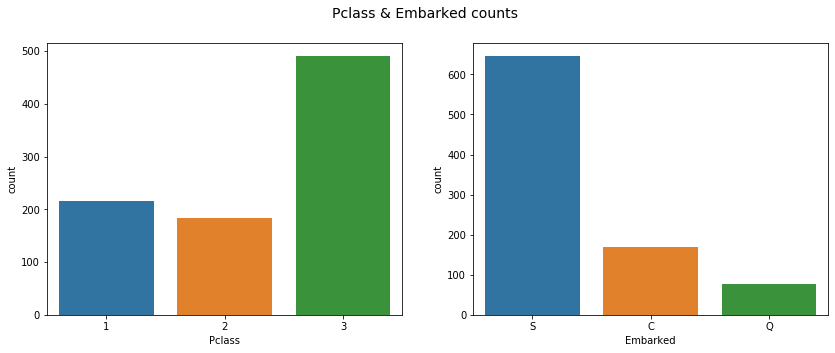

In [38]:
fig,axs = plt.subplots(1,2,figsize=(14,5))
axs = axs.flatten()
plt.suptitle('Pclass & Embarked counts',fontsize=14)
cols = ['Pclass','Embarked']
for col,ind in zip(cols,range(len(cols))):
    sns.countplot(x=train_df[col],ax=axs[ind])
    
    

    Can you make anything of the above plot? In the Data Science jargon - what are the insights from above plot?
---

    There can be many insights, these are readily inferred:
        1. Class 3 has the highest # passengers, that can say order of luxury(highest to lowest): 1,2,3
        2. It is highly likely that most people from class 3 embarked at 'S'
        
    And Finally! The voyage begins, so does the story...

In [273]:
#Let's make a copy of the original dataframe and make bins whereever possible in the copy
data_bins = train_df.copy(deep=True)
data_bins.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,Last_Name
0,0,3,male,22,1,0,7.2500,S,Mr,Braund
1,1,1,female,38,1,0,71.2833,C,Mrs,Cumings
2,1,3,female,26,0,0,7.9250,S,Miss,Heikkinen
3,1,1,female,35,1,0,53.1000,S,Mrs,Futrelle
4,0,3,male,35,0,0,8.0500,S,Mr,Allen


    When working with continous values becomes hard, binning is a great workaround. Are there any variables that would make our life easy with binning?
---

    Age and Fare could use with some binning

In [274]:
data_bins['Age'] = pd.cut(data_bins['Age'],[0,15,25,35,45,60,80])
data_bins['Fare'] = pd.cut(data_bins['Fare'],[0,10,20,35,60,80,100,200,300,400,515])
data_bins.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,Last_Name
0,0,3,male,"(15, 25]",1,0,"(0, 10]",S,Mr,Braund
1,1,1,female,"(35, 45]",1,0,"(60, 80]",C,Mrs,Cumings
2,1,3,female,"(25, 35]",0,0,"(0, 10]",S,Miss,Heikkinen
3,1,1,female,"(25, 35]",1,0,"(35, 60]",S,Mrs,Futrelle
4,0,3,male,"(25, 35]",0,0,"(0, 10]",S,Mr,Allen


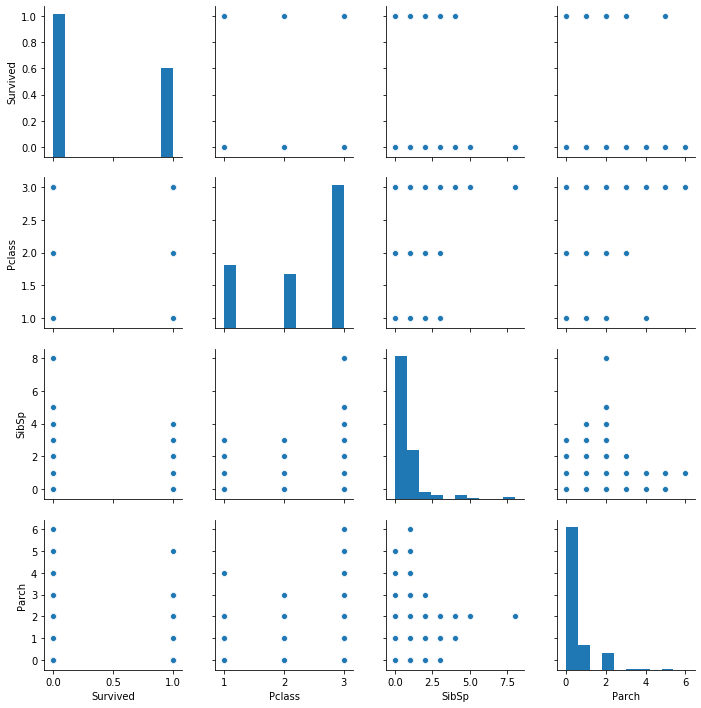

In [210]:
sns.pairplot(data_bins)

    What can you make of the pairplot above?
---
    
    It might not be a good idea to use pairplots everytime to notice correlation. When the variables are continious a scatter plot shows pattern if present else the absence of pattern becomes obvious. But the features we were looking at are all ordinal so the pattern might not be clearly understood.
    
    There is a distinct relation between parch and sibsp: to an extent they are positively related and then as parch incrases sibsp reduces because when both the parents go chances are their kids go with them and not siblings


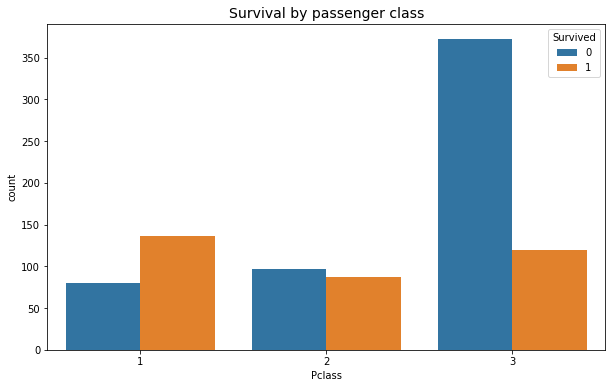

In [215]:
plt.figure(figsize=(10,6))
plt.title('Survival by passenger class',fontsize=14)
sns.countplot(x=data_bins['Pclass'],hue=data_bins['Survived'])

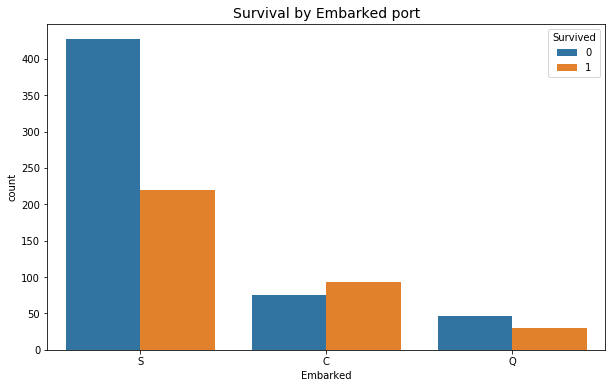

In [216]:
plt.figure(figsize=(10,6))
plt.title('Survival by Embarked port',fontsize=14)
sns.countplot(x=data_bins['Embarked'],hue=data_bins['Survived'])

    Based on our analysis till now, what can you say from the above plots?
---

    Class 3 & S has most deaths given the number of passengers. We can now say that the passengers in class 3 are in the most dangerous location of the ship

In [233]:
data_bins['one'] = 1
grouped = data_bins.groupby(by='Last_Name')[['Last_Name','Survived','one']].sum()
grouped['survival_rate'] = grouped['Survived']/grouped['one']
grouped.reset_index(inplace=True)

In [249]:
grouped[grouped['one']>2].sort_values(by='survival_rate',ascending=False)

,Last_Name,Survived,one,survival_rate
32,Baclini,4,4,1.000000
507,Richards,3,3,1.000000
306,Kelly,3,4,0.750000
25,Asplund,3,4,0.750000
76,Brown,3,4,0.750000
239,Harper,3,4,0.750000
327,Laroche,2,3,0.666667
271,Hoyt,2,3,0.666667
428,Navratil,2,3,0.666667
430,Newell,2,3,0.666667


    From the above table, we can notice there are many Last_names possibly belonging to 3 class or the Last_names having highest survival rate are some of the most prominant or important people

## Modeling

In [253]:
data_bins.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
Survived     891 non-null int64
Pclass       891 non-null int64
Sex          891 non-null object
Age          884 non-null category
SibSp        891 non-null int64
Parch        891 non-null int64
Fare         876 non-null category
Embarked     891 non-null object
Title        891 non-null object
Last_Name    891 non-null object
one          891 non-null int64
dtypes: category(2), int64(5), object(4)
memory usage: 65.2+ KB


    Let's convert Pclass to category type

In [276]:
data_bins['Pclass'] = data_bins['Pclass'].astype('category')
data_bins['Age'] = data_bins['Age'].astype('category')
data_bins['Fare'] = data_bins['Fare'].astype('category')

In [277]:
data_ohe = data_bins.drop(labels=['Last_Name'],axis=1).copy()
data_ohe = pd.get_dummies(data_ohe)
data_ohe.tail()

,Survived,SibSp,Parch,one,Pclass_1,Pclass_2,Pclass_3,...,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Top
886,0,0,0,1,0,1,0,...,0,1,0,0,0,0,1
887,1,0,0,1,1,0,0,...,0,1,0,1,0,0,0
888,0,1,2,1,0,0,1,...,0,1,0,1,0,0,0
889,1,0,0,1,1,0,0,...,0,0,0,0,1,0,0
890,0,0,0,1,0,0,1,...,1,0,0,0,1,0,0


In [279]:
data_bins['Age'] = data_bins['Age'].astype(str)
data_bins['Fare'] = data_bins['Fare'].astype(str)

In [280]:
le = LabelEncoder()
data_le = data_bins.copy(deep=True)
data_le[['Title','Sex','Age','Fare','Embarked']] = data_le[['Title','Sex','Age','Fare','Embarked']].apply(le.fit_transform)
data_le.tail()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,Last_Name,one
886,0,2,1,2,0,0,1,2,4,Montvila,1
887,1,1,0,1,0,0,3,2,1,Graham,1
888,0,3,0,1,1,2,3,2,1,Johnston,1
889,1,1,1,2,0,0,3,0,2,Behr,1
890,0,3,1,2,0,0,0,1,2,Dooley,1


    What is the benefit of converting the original data with one hot encoding or any other encoding technique?

In [305]:
X_test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [311]:
X_test = pd.read_csv('/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/DataTales/DT01-Titanic/test_titanic.csv')

X_test['Title']= X_test['Name'].apply(lambda val: val.split(',')[1].split('.')[0].strip())

X_test['Title'].replace({'Ms':'Miss'},inplace=True)
X_test['Title'].replace(['Dona','Dr','Rev','Major','Col','Mlle','Lady','Mme','Capt','Jonkheer','the Countess','Don','Sir'],'Top',
                            inplace=True)

X_test.drop(labels=['Name','Cabin','Ticket'],axis=1,inplace=True)

X_test['Age'] = pd.cut(X_test['Age'],[0,15,25,35,45,60,80])
X_test['Fare'] = pd.cut(X_test['Fare'],[0,10,20,35,60,80,100,200,300,400,515])
X_test['Pclass'] = X_test['Pclass'].astype('category')
X_test['Age'] = X_test['Age'].astype('category')
X_test['Fare'] = X_test['Fare'].astype('category')


X_test = pd.get_dummies(X_test)


X_test.head()


,PassengerId,SibSp,Parch,Pclass_1,Pclass_2,Pclass_3,Sex_female,...,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Top
0,892,0,0,0,0,1,0,...,1,0,0,0,1,0,0
1,893,1,0,0,0,1,1,...,0,1,0,0,0,1,0
2,894,0,0,0,1,0,0,...,1,0,0,0,1,0,0
3,895,0,0,0,0,1,0,...,0,1,0,0,1,0,0
4,896,1,1,0,0,1,1,...,0,1,0,0,0,1,0


In [258]:
def run_model(name,X_train,y_train,cv):
    '''Applies the model specified in NAME on the X_train, y_train
    with cross-validation #cv times and returns accuracy'''
        
    #running cross validation model
    cv_pred = model_selection.cross_val_predict(name, X_train, y_train,
                                                cv = cv, n_jobs = -1)
    cv_accuracy = round(metrics.accuracy_score(cv_pred,y_train)*100,2)
    
    return cv_accuracy

### Logistic Regression

In [286]:
X_train_le = data_le.loc[:,'Pclass':'Title']
y_train_le = data_le['Survived']
cv_acc = run_model(LogisticRegression(),X_train_le,y_train_le,10)
print('Logistic Regression LE: ',cv_acc)


X_train = data_ohe.loc[:,'SibSp':'Title_Top']
y_train = data_ohe['Survived']
cv_acc = run_model(LogisticRegression(),X_train,y_train,10)
print('Logistic Regression OHE: ',cv_acc)

Logistic Regression LE:  79.46
Logistic Regression OHE:  81.37


### SVD

In [322]:
sgd = linear_model.SGDClassifier(max_iter=5, tol=None) 
cv_acc = run_model(sgd,X_train_le,y_train_le,10)
print('SVD LE: ',cv_acc)

sgd = linear_model.SGDClassifier(max_iter=5, tol=None) 
cv_acc = run_model(sgd,X_train_le,y_train_le,10)
print('SVD OHE: ',cv_acc)

SVD LE:  73.18
SVD OHE:  70.71


### KNN

In [323]:
knn = KNeighborsClassifier(n_neighbors = 3)
cv_acc = run_model(knn,X_train_le,y_train_le,10)
print('KNN LE: ',cv_acc)

knn = KNeighborsClassifier(n_neighbors = 3)
cv_acc = run_model(knn,X_train_le,y_train_le,10)
print('KNN OHE: ',cv_acc)

KNN LE:  77.67
KNN OHE:  77.67


### DecisionTree

In [324]:
cv_acc = run_model(DecisionTreeClassifier(),X_train_le,y_train_le,10)
print('DecesionTreeClassifier LE: ',cv_acc)

cv_acc = run_model(DecisionTreeClassifier(),X_train,y_train,10)
print('DecesionTreeClassifier OHE: ',cv_acc)

DecesionTreeClassifier LE:  78.56
DecesionTreeClassifier OHE:  78.9


### RandomForest

In [325]:
cv_acc = run_model(RandomForestClassifier(),X_train_le,y_train_le,10)
print('RandomForestClassifier LE: ',cv_acc)

cv_acc = run_model(RandomForestClassifier(),X_train,y_train,10)
print('RandomForestClassifier OHE: ',cv_acc)

RandomForestClassifier LE:  80.25
RandomForestClassifier OHE:  80.92


In [ ]:
param_grid = { "criterion" : ["gini", "entropy"],
              "min_samples_leaf" : [1, 5, 10, 25, 50, 70],
              "min_samples_split" : [2, 4, 10, 12, 16, 18, 25, 35], 
              "n_estimators": [100, 400, 700, 1000, 1500]}

from sklearn.model_selection import GridSearchCV, cross_val_score
rf = RandomForestClassifier(n_estimators=100, max_features='auto', oob_score=True, random_state=1, n_jobs=-1)
clf = GridSearchCV(estimator=rf, param_grid=param_grid, n_jobs=-1)
clf.fit(X_train, y_train)



In [319]:
clf.best_params_

{'criterion': 'entropy',
 'min_samples_leaf': 1,
 'min_samples_split': 10,
 'n_estimators': 400}

In [321]:
#Let's tune the RandomForest hyperparameters
random_forest = RandomForestClassifier(criterion = "entropy", 
                                       min_samples_leaf = 1, 
                                       min_samples_split = 10,   
                                       n_estimators=400, 
                                       max_features='auto', 
                                       n_jobs=-1)


cv_acc = run_model(random_forest,X_train,y_train,10)
print('Best RandomForest accuracy: ',cv_acc)

Best RandomForest accuracy:  82.72


    After tuning there's a 2% increase in the accuracy. Do you think that is good? if it isn't what can you do to improve it?

### Conclusion:
    All our model's scores ranged between 70 and 82%. It is important to note we haven't done much of tuning but enough to understand that tuning can improves performance. More ways to improve performance can be to use advanced models, tuning with even more paramenter options.